# MNIST Handwritten Digit Classification Using a Neural Network

## AI-ML Recruitment Task 2026

This project builds a simple neural network to classify handwritten digits from 0 to 9 using the MNIST dataset.

### Objectives
- Understand the MNIST dataset
- Preprocess image data
- Build a simple neural network
- Use ReLU and Softmax activation functions
- Evaluate the model using accuracy and confusion matrix
- Experiment with a change in the model architecture

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 1. Dataset Understanding

MNIST is a dataset of handwritten digits from 0 to 9. Each image is grayscale and has dimensions of 28 × 28 pixels.

The dataset contains 10 classes, corresponding to the digits 0 through 9.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


### Sample Images

Each MNIST image contains 28 × 28 grayscale pixels. The corresponding label represents the digit shown in the image.

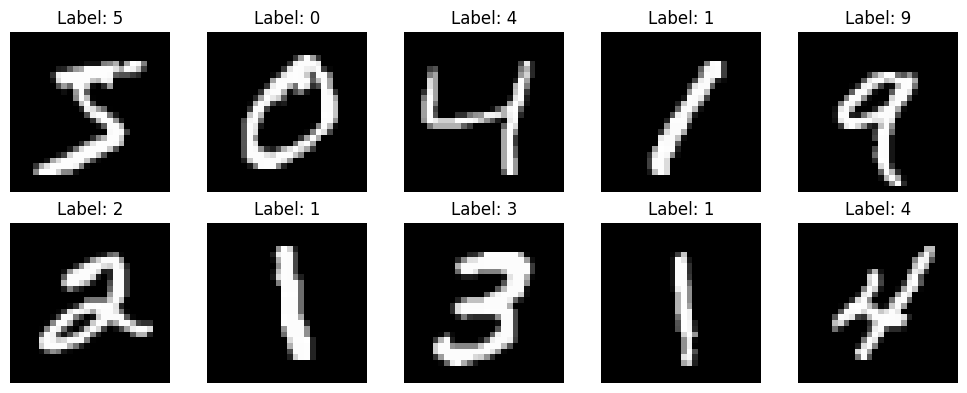

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 2. Building the Neural Network

The neural network consists of:

- A Flatten layer to convert each 28 × 28 image into a 784-element vector
- A hidden Dense layer containing 128 neurons with ReLU activation
- An output Dense layer containing 10 neurons with Softmax activation

ReLU is used in the hidden layer to introduce non-linearity.

Softmax is used in the output layer because this is a multi-class classification problem involving 10 possible digits.

In [5]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

c:\Users\fameg\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9211 - loss: 0.2750 - val_accuracy: 0.9645 - val_loss: 0.1285
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9635 - loss: 0.1244 - val_accuracy: 0.9732 - val_loss: 0.0930
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9750 - loss: 0.0845 - val_accuracy: 0.9722 - val_loss: 0.0927
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9804 - loss: 0.0630 - val_accuracy: 0.9777 - val_loss: 0.0802
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9848 - loss: 0.0499 - val_accuracy: 0.9757 - val_loss: 0.0816
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9880 - loss: 0.0386 - val_accuracy: 0.9787 - val_loss: 0.0767
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9906 - loss: 0.0305 - val_accuracy: 0.9773 - val_loss: 0.0846
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9923 - loss: 0.0251 - 

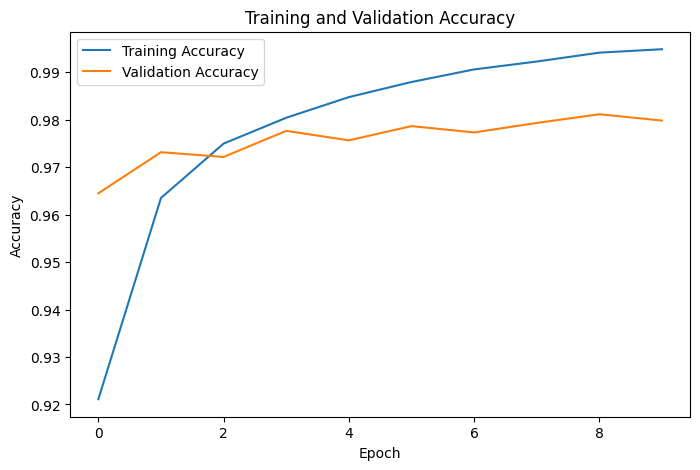

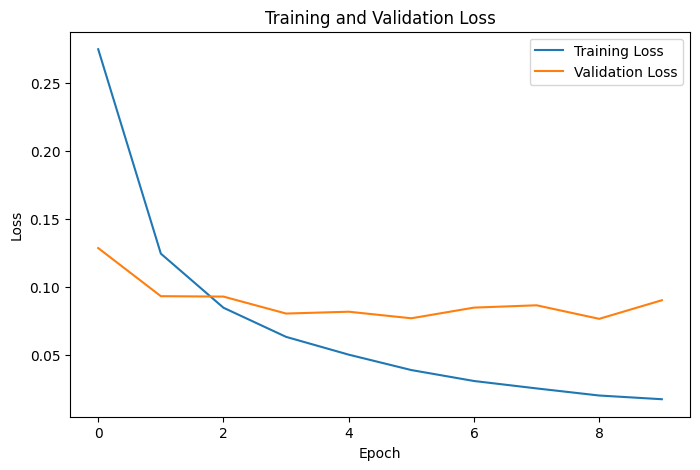

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.09569747745990753
Test Accuracy: 0.9753000140190125


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 811us/step


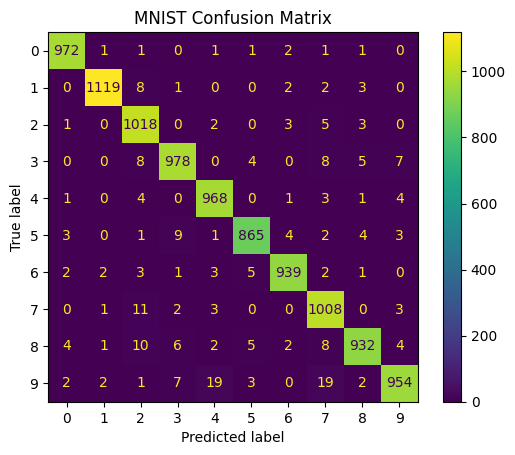

In [10]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title("MNIST Confusion Matrix")
plt.show()

In [11]:
experiment_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation="relu"),
    Dense(10, activation="softmax")
])

experiment_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

experiment_loss, experiment_accuracy = experiment_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Experiment Test Loss:", experiment_loss)
print("Experiment Test Accuracy:", experiment_accuracy)

c:\Users\fameg\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Experiment Test Loss: 2.4303972721099854
Experiment Test Accuracy: 0.08060000091791153


In [12]:
print("Original Model Accuracy:", test_accuracy)
print("Experiment Model Accuracy:", experiment_accuracy)

Original Model Accuracy: 0.9753000140190125
Experiment Model Accuracy: 0.08060000091791153


## Conclusion

The neural network successfully classified handwritten digits from the MNIST dataset. The images were normalized and passed through a simple neural network consisting of a Flatten layer, a hidden Dense layer using ReLU, and an output layer using Softmax.

The model achieved strong classification performance on the test dataset. The confusion matrix showed that most digits were correctly classified, with a small number of misclassifications between visually similar digits.

The experiment demonstrated how changing the number of neurons in the hidden layer can affect model performance.